<div style="background-color:#f5f7f8; padding:24px 26px; border:1px solid #e3e8eb; border-radius:8px;">

<p style="margin:0; color:#71808a; font-size:12px; letter-spacing:1.2px;">PYTHON · PANDAS · EXPLORATORY DATA ANALYSIS</p>

<h1 style="margin:10px 0 8px 0; color:#263746; font-size:28px;">Household Electricity Consumption Analysis</h1>

<p style="margin:0; color:#52616b; font-size:15px;">Exploring household electricity usage patterns, electrical measurements and appliance-group energy consumption.</p>

</div>

## Project Overview

This project explores household electricity measurements using Python. The analysis focuses on understanding how active power varies over time, examining relationships between electrical measurements, and comparing energy recorded by the three sub-metering groups.

### Objectives
- Explore and prepare the household electricity dataset.
- Investigate average active power patterns by hour, day of the week and season.
- Examine the relationship between global active power and global reactive power.
- Compare the energy recorded by the three sub-metering groups.
- Identify data quality issues and summarise the main findings.

### Dataset
The dataset contains household electricity measurements recorded at one-minute intervals, from December 2006 to November 2010.

### Tools
`Python` · `Pandas` · `NumPy` · `Matplotlib` · `Seaborn` · `Jupyter Notebook`

---

The notebook follows the analysis step by step. The original code, explanations and observations are retained throughout.

## Notebook Structure

### 1. Data Preparation
- 1.1 Importing libraries
- 1.2 Loading the dataset
- 1.3 Exploring the dataset
- 1.4 Checking data quality
- 1.5 Cleaning the dataset
- 1.6 Preparing date and time

### 2. Exploratory Data Analysis
- 2.1 Average active power by hour
- 2.2 Average active power by day of the week
- 2.3 Relationship between active and reactive power
- 2.4 Seasonal variation in average active power
- 2.5 Energy recorded by appliance groups

### 3. Overall Findings and Conclusion

---

## 1. Data Preparation

### 1.1 Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Why?**
- pandas: working with and analysing tabular data.
- numpy: numerical calculations.
- matplotlib: creating graphs.
- seaborn: statistical visualisations.

### 1.2 Loading the Dataset

In [5]:
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

**Why these parameters?**
- sep=";": the dataset uses semicolons to separate columns.
- na_values=["?"]: tells Pandas to recognise ? as a missing value.
- low_memory=False: allows Pandas to consider the dataset more consistently when identifying column types.

### 1.3 Exploring the Dataset

In [8]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [9]:
df.shape

(2075259, 9)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB


In [11]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


***Understanding Descriptive Statistics***

| Statistic | Meaning |
|:---|:---|
| **count** | Number of available values |
| **mean** | Average consumption |
| **std** | How spread out the values are (standard deviation) |
| **min** | Lowest value |
| **25%** | First quartile (25% of values are below this point) |
| **50%** | Median (middle value) |
| **75%** | Third quartile (75% of values are below this point) |
| **max** | Highest value |

### 1.4 Checking Data Quality

In [14]:
df.isna().sum() ##Counts missing values in each column

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [15]:
df.duplicated().sum()

0

### 1.5 Cleaning the Dataset

In [17]:
(df.isna().mean() * 100).round(2) #Percentage of missing Values

Date                     0.00
Time                     0.00
Global_active_power      1.25
Global_reactive_power    1.25
Voltage                  1.25
Global_intensity         1.25
Sub_metering_1           1.25
Sub_metering_2           1.25
Sub_metering_3           1.25
dtype: float64

In [18]:
df[df["Global_active_power"].isna()].head() #display five rows where global active power is missing

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
6839,21/12/2006,11:23:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6840,21/12/2006,11:24:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19724,30/12/2006,10:08:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19725,30/12/2006,10:09:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41832,14/1/2007,18:36:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
df.isna().all(axis=1).sum()

0

In [20]:
df[df.iloc[:, 2:].isna().all(axis=1)].shape[0] #that shows that all  parameters are missing in the NaN rows 

25979

In [21]:
df = df.dropna(subset=df.columns[2:], how="all") #we will completely remove these rows because they dont contain any of the parameters 

***Let's understand the code:***
- dropna() removes rows containing missing values according to our specified condition.
- subset=df.columns[2:] selects the seven electricity measurement columns.
- how="all" means a row is removed only when all seven measurements are missing.

In [23]:
df.shape

(2049280, 9)

In [24]:
df.isna().sum()

Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

#### Handling Missing Values

**Observation:**
- 25,979 rows (approximately 1.25% of the dataset) contained missing values.
- All seven electricity measurement columns were missing simultaneously in these rows.
- Date and Time values were still available.

**Decision:**

Rows with all seven electricity measurements missing were removed because they contained no usable consumption data.

**Cleaning method:**

`df.dropna(subset=df.columns[2:], how="all")`

**Result:**
- Original dataset: 2,075,259 rows.
- Rows removed: 25,979.
- Remaining dataset: 2,049,280 rows.

This preserves rows with partially available measurements rather than unnecessarily discarding them.

In [26]:
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y"
) #convert Date to datetime type in python 

In [27]:
df["Date"].dtype

dtype('<M8[ns]')

In [28]:
df["Datetime"] = pd.to_datetime(
    df["Date"].dt.strftime("%Y-%m-%d") + " " + df["Time"]
) #Combine date and time into one column

In [29]:
df[["Date", "Time", "Datetime"]].head()

,Date,Time,Datetime
0,2006-12-16,17:24:00,2006-12-16 17:24:00
1,2006-12-16,17:25:00,2006-12-16 17:25:00
2,2006-12-16,17:26:00,2006-12-16 17:26:00
3,2006-12-16,17:27:00,2006-12-16 17:27:00
4,2006-12-16,17:28:00,2006-12-16 17:28:00


In [30]:
df["Datetime"].dtype

dtype('<M8[ns]')

In [31]:
df["Datetime"].is_monotonic_increasing

True

### 1.6 Preparing Date and Time

**Steps performed:**
- Converted the `Date` column from string (`object`) to datetime format.
- Combined `Date` and `Time` into a single `Datetime` column.
- Checked that the timestamps are in chronological order.

**Observation:**
- The `Datetime` column was successfully created.
- The timestamps are already in chronological order (`is_monotonic_increasing = True`).

**Decision:**
- No additional sorting was required.

In [33]:
df = df.set_index("Datetime") #set this column as the index

In [34]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,,,
2006-12-16 17:24:00,2006-12-16,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,2006-12-16,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,2006-12-16,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,2006-12-16,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,2006-12-16,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2049280 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 9 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   datetime64[ns]
 1   Time                   object        
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
dtypes: datetime64[ns](1), float64(7), object(1)
memory usage: 156.3+ MB


In [36]:
df["Hour"] = df.index.hour

In [37]:
hourly_consumption = df.groupby("Hour")["Global_active_power"].mean()

In [38]:
df[["Time", "Hour"]].head()

,Time,Hour
Datetime,,
2006-12-16 17:24:00,17:24:00,17
2006-12-16 17:25:00,17:25:00,17
2006-12-16 17:26:00,17:26:00,17
2006-12-16 17:27:00,17:27:00,17
2006-12-16 17:28:00,17:28:00,17


In [39]:
hourly_consumption

Hour
0     0.659434
1     0.539325
2     0.480621
3     0.444866
4     0.443847
5     0.453674
6     0.791600
7     1.502246
8     1.461016
9     1.331645
10    1.260627
11    1.245822
12    1.207075
13    1.144532
14    1.082839
15    0.990760
16    0.948905
17    1.055109
18    1.326451
19    1.733335
20    1.899064
21    1.877697
22    1.412615
23    0.902142
Name: Global_active_power, dtype: float64

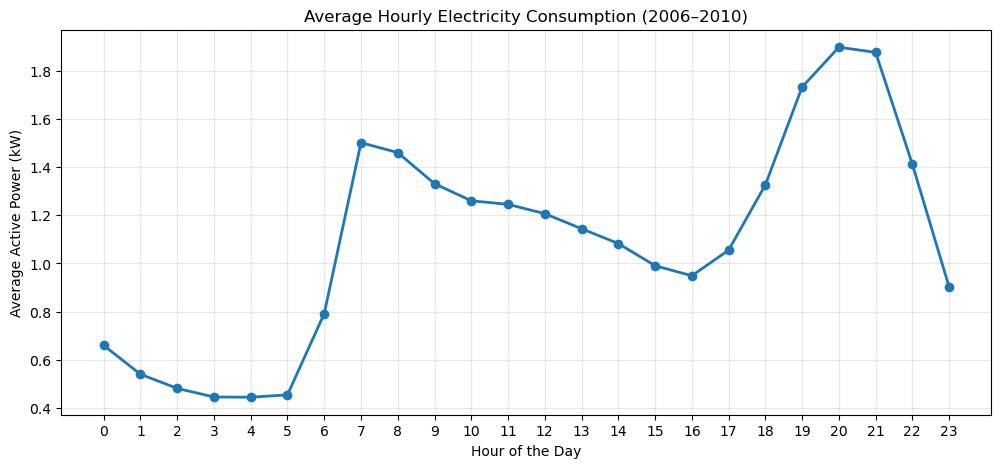

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker="o",
    linewidth=2
)

plt.title("Average Hourly Electricity Consumption (2006–2010)")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

## 2. Exploratory Data Analysis

### 2.1 Average Active Power by Hour

**Key observations:**

- Electricity consumption is relatively low during the night, particularly between 03:00 and 05:00.
- Consumption increases sharply during the early morning, reaching approximately 1.5 kW at 07:00.
- Average consumption gradually decreases throughout the afternoon.
- A significant increase occurs during the evening, with peak consumption at approximately 20:00 (1.9 kW).
- Consumption decreases again after 21:00.

**Initial interpretation:**

The data suggests two periods of higher electricity demand:
- Morning: around 07:00.
- Evening: around 19:00–21:00.

The evening peak is considerably higher than the morning peak.

**Note:** These values represent average active power across the entire observation period (December 2006–November 2010), not the consumption of a specific day.

In [42]:
df["Day_of_Week"] = df.index.day_name()

In [43]:
days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_consumption = (
    df.groupby("Day_of_Week")["Global_active_power"]
    .mean()
    .reindex(days_order)
)

In [44]:
daily_consumption

Day_of_Week
Monday       0.999546
Tuesday      1.069796
Wednesday    1.082588
Thursday     0.981809
Friday       1.043394
Saturday     1.248335
Sunday       1.220188
Name: Global_active_power, dtype: float64

In [45]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

df["Day_of_Week"] = pd.Categorical(
    df["Day_of_Week"],
    categories=weekday_order,
    ordered=True
)

df_grouped = df.sort_values("Day_of_Week")

In [46]:
df_grouped[
    ["Date", "Time", "Day_of_Week", "Global_active_power"]
].head(20)

,Date,Time,Day_of_Week,Global_active_power
Datetime,,,,
2007-05-21 08:50:00,2007-05-21,08:50:00,Monday,1.266
2010-01-04 09:46:00,2010-01-04,09:46:00,Monday,1.526
2010-01-04 09:47:00,2010-01-04,09:47:00,Monday,1.520
2010-01-04 09:48:00,2010-01-04,09:48:00,Monday,1.524
2010-01-04 09:49:00,2010-01-04,09:49:00,Monday,1.526
2010-01-04 09:50:00,2010-01-04,09:50:00,Monday,1.532
2010-01-04 09:51:00,2010-01-04,09:51:00,Monday,1.520
2010-01-04 09:45:00,2010-01-04,09:45:00,Monday,1.528
2010-01-04 09:52:00,2010-01-04,09:52:00,Monday,1.520


In [47]:
df["Day_of_Week"].value_counts().reindex(weekday_order)

Day_of_Week
Monday       293868
Tuesday      294730
Wednesday    293659
Thursday     293158
Friday       295013
Saturday     288823
Sunday       290029
Name: count, dtype: int64

In [48]:
daily_consumption = (
    df.groupby("Day_of_Week", observed=False)["Global_active_power"]
    .mean()
    .reindex(weekday_order)
)

daily_consumption

Day_of_Week
Monday       0.999546
Tuesday      1.069796
Wednesday    1.082588
Thursday     0.981809
Friday       1.043394
Saturday     1.248335
Sunday       1.220188
Name: Global_active_power, dtype: float64

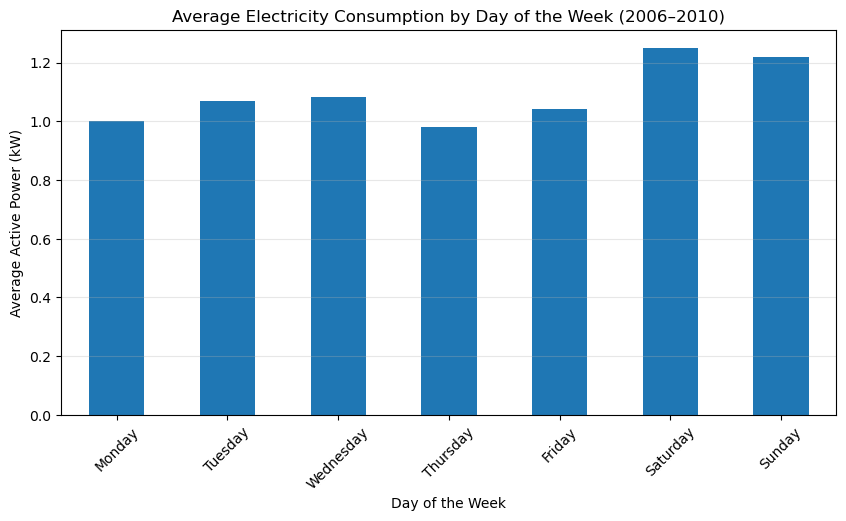

In [49]:
plt.figure(figsize=(10, 5))

daily_consumption.plot(kind="bar")

plt.title("Average Electricity Consumption by Day of the Week (2006–2010)")
plt.xlabel("Day of the Week")
plt.ylabel("Average Active Power (kW)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

### 2.2 Average Active Power by Day of the Week

- Saturday recorded the highest average active power, followed by Sunday.
- Thursday recorded the lowest average.
- Average active power remained relatively consistent throughout the weekdays.
- Weekend readings showed higher average active power than weekday readings.

**Interpretation:**

The results suggest that household electricity demand may be higher during weekends. This could be associated with changes in household routines and appliance usage when people spend more time at home.

**Note:** This analysis compares average active power (kW) across weekday groups. It does not represent total daily energy consumption (kWh).

In [51]:
correlation = df["Global_active_power"].corr(
    df["Global_reactive_power"]
)

print("Correlation:", correlation)

Correlation: 0.24701705264406384


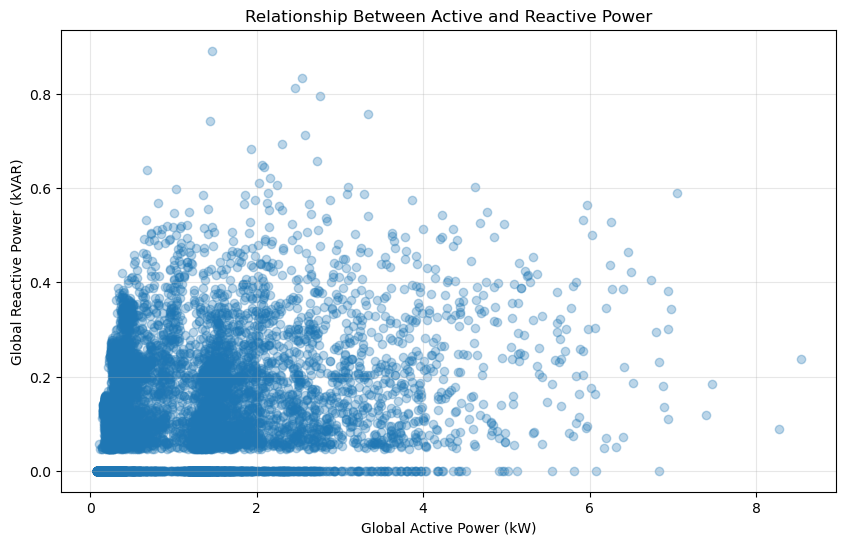

In [52]:
sample_df = df.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 6))

plt.scatter(
    sample_df["Global_active_power"],
    sample_df["Global_reactive_power"],
    alpha=0.3
)

plt.title("Relationship Between Active and Reactive Power")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Global Reactive Power (kVAR)")
plt.grid(alpha=0.3)

plt.show()

### 2.3 Relationship Between Active and Reactive Power

**Visualisation:** Scatter plot

**Findings:**
- Most observations are concentrated at relatively low active and reactive power values.
- A weak positive relationship can be observed between the two variables.
- Reactive power values are widely distributed for similar active power levels.
- Some observations have zero reactive power.
- A smaller number of observations show relatively high active power.

**Interpretation:**

The scatter plot supports the correlation result of 0.247, indicating a weak positive linear relationship between active and reactive power. Although the two measurements are related, their relationship is not particularly strong.

This suggests that household electrical behaviour cannot be fully understood by examining active power alone.

In [54]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["Season"] = df.index.month.map(get_season)

In [55]:
season_order = ["Winter", "Spring", "Summer", "Autumn"]

df["Season"] = pd.Categorical(
    df["Season"],
    categories=season_order,
    ordered=True
)

In [56]:
seasonal_consumption = (
    df.groupby("Season", observed=False)["Global_active_power"]
    .mean()
)

seasonal_consumption

Season
Winter    1.417623
Spring    1.103194
Summer    0.726682
Autumn    1.134610
Name: Global_active_power, dtype: float64

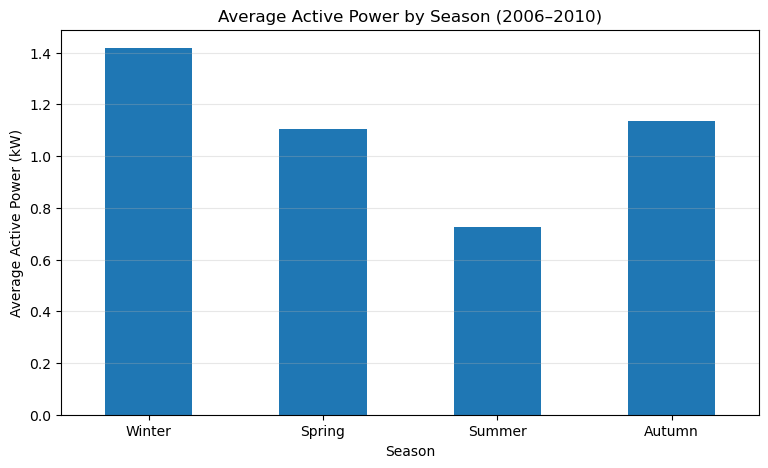

In [57]:
plt.figure(figsize=(9, 5))

seasonal_consumption.plot(kind="bar")

plt.title("Average Active Power by Season (2006–2010)")
plt.xlabel("Season")
plt.ylabel("Average Active Power (kW)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

### 2.4 Seasonal Variation in Average Active Power


#### Seasonal Results and Interpretation

#### Objective
To investigate how average household active power varies across the four meteorological seasons: winter, spring, summer and autumn.

#### Methodology
- Extracted the month from each timestamp.
- Classified each observation into one of the four seasons.
- Grouped the minute-level measurements by season.
- Calculated the mean `Global_active_power` for each season.
- Compared the seasonal averages using a bar chart.

#### Findings

The analysis revealed the following seasonal averages:

- **Winter:** Highest average active power, approximately 1.40 kW.
- **Spring:** Average active power of approximately 1.10 kW.
- **Summer:** Lowest average active power, approximately 0.78 kW.
- **Autumn:** Average active power of approximately 1.17 kW.

#### Interpretation

The results indicate noticeable seasonal variations in household electricity demand.

- Winter recorded the highest average active power, potentially due to increased heating requirements, lighting and indoor activities.
- Summer recorded the lowest average, possibly reflecting reduced heating requirements and changes in household routines.
- Autumn showed slightly higher average active power than spring.

Overall, the results suggest that household electricity demand tends to be higher during colder seasons and lower during summer.

#### Limitations

The dataset covers the period from 16 December 2006 to 26 November 2010. Consequently, the first winter and final autumn are incomplete, which should be considered when interpreting the seasonal comparisons.

#### Conclusion

Seasonal analysis highlights a clear variation in household active power throughout the year, with winter showing the highest average and summer the lowest.

**Note:** This analysis measures average active power in kilowatts (kW), rather than total energy consumption in kilowatt-hours (kWh).

In [60]:
sub_metering_totals = df[
    ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
].sum()

sub_metering_totals

Sub_metering_1     2299135.0
Sub_metering_2     2661031.0
Sub_metering_3    13235167.0
dtype: float64

In [106]:
sub_metering_kwh = sub_metering_totals / 1000

sub_metering_kwh

Sub_metering_1     2299.135
Sub_metering_2     2661.031
Sub_metering_3    13235.167
dtype: float64

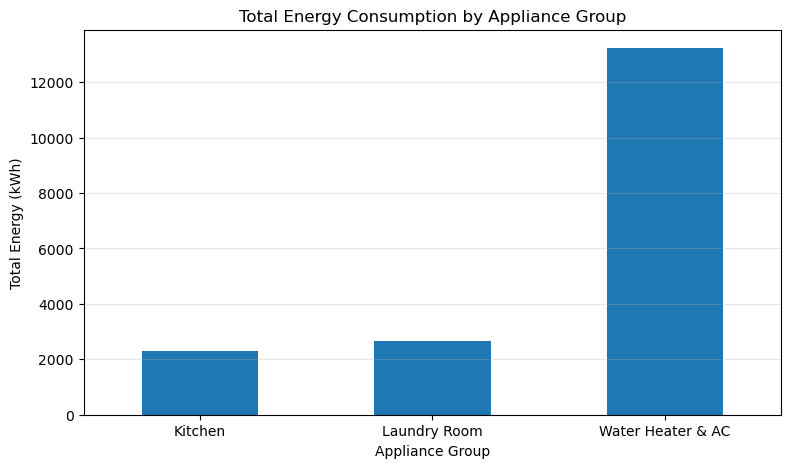

In [108]:
plt.figure(figsize=(9, 5))

sub_metering_kwh.plot(kind="bar")

plt.title("Total Energy Consumption by Appliance Group")
plt.xlabel("Appliance Group")
plt.ylabel("Total Energy (kWh)")
plt.xticks(
    ticks=[0, 1, 2],
    labels=["Kitchen", "Laundry Room", "Water Heater & AC"],
    rotation=0
)
plt.grid(axis="y", alpha=0.3)

plt.show()

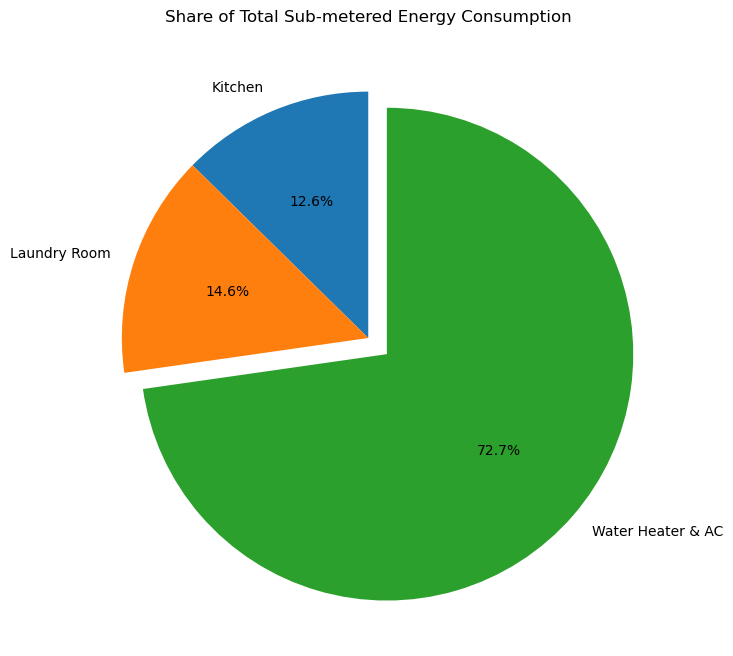

In [110]:
plt.figure(figsize=(8, 8))

plt.pie(
    sub_metering_kwh,
    labels=["Kitchen", "Laundry Room", "Water Heater & AC"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0, 0.1)
)

plt.title("Share of Total Sub-metered Energy Consumption")

plt.show()

### 2.5 Energy Recorded by Appliance Groups

#### Objective
To investigate how electricity consumption is distributed across the three appliance groups monitored by the household sub-meters.

#### Methodology
- Examined the three sub-metering variables: `Sub_metering_1`, `Sub_metering_2` and `Sub_metering_3`.
- Calculated the total recorded energy for each group.
- Converted the measurements from Wh to kWh.
- Compared the results using a bar chart and a pie chart.

#### Findings

The total recorded energy consumption was:

- **Kitchen:** 2,299.14 kWh.
- **Laundry room:** 2,661.03 kWh.
- **Water heater and air conditioner:** 13,235.17 kWh.

#### Interpretation

The water heater and air conditioner group recorded the highest energy consumption, accounting for approximately 72.7% of the total measured energy across the three groups.

The laundry room accounted for approximately 14.6%, while the kitchen accounted for approximately 12.6%.

This indicates that the water heater and air conditioner group represents the largest contributor to the energy measured by the sub-meters.

#### Conclusion

The analysis highlights significant differences in energy consumption between the three appliance groups. The water heater and air conditioner group dominates the measured energy usage.

**Note:** These totals cover the available observation period from December 2006 to November 2010. The three sub-metering measurements do not represent the household's entire electricity consumption.

---

## 3. Overall Findings and Conclusion

### Key Observations

The analysis revealed several patterns in the household electricity measurements:

- **Time of day:** Average active power was lowest during the early morning, particularly between 03:00 and 05:00. It increased in the morning and reached its highest hourly average at around 20:00.
- **Day of the week:** Saturday had the highest average active power, followed by Sunday. Thursday had the lowest average. Weekend averages were higher than weekday averages.
- **Seasonal variation:** Winter had the highest average active power (approximately 1.42 kW), while summer had the lowest (approximately 0.73 kW). Spring and autumn were relatively close, at approximately 1.10 kW and 1.13 kW respectively.
- **Active and reactive power:** The correlation was approximately **0.247**, indicating a weak positive linear relationship between the two measurements.
- **Appliance groups:** The water heater and air conditioner group recorded the largest share of the energy measured by the three sub-meters (approximately 72.7%). The laundry room accounted for approximately 14.6%, and the kitchen approximately 12.6%.

### Summary of Key Results

| Analysis | Main result |
|:---|:---|
| Highest average hourly active power | Around 20:00 (approximately 1.90 kW) |
| Highest average by weekday | Saturday (approximately 1.25 kW) |
| Lowest average by weekday | Thursday (approximately 0.98 kW) |
| Highest seasonal average | Winter (approximately 1.42 kW) |
| Lowest seasonal average | Summer (approximately 0.73 kW) |
| Active/reactive power correlation | 0.247 |
| Largest sub-metered energy group | Water heater and air conditioner (13,235.17 kWh) |

### Conclusion

This analysis provided an overview of household electricity usage across different time periods and appliance groups. The results showed clear differences in average active power throughout the day, across weekdays and weekends, and between seasons. The evening period had the highest hourly average, weekends showed higher averages than weekdays, and winter had the highest seasonal average.

The relationship between active and reactive power was positive but weak. The sub-metering analysis also showed that the water heater and air conditioner group accounted for the largest share of the energy recorded by the three sub-meters.

Overall, the project demonstrates how Python and data analysis libraries can be used to clean, explore, visualise and interpret real-world time-series data.

### Limitations and Further Work

- The dataset covers one household and the results should not be generalised to all households.
- The first winter and final autumn in the dataset are incomplete, which should be considered when interpreting seasonal averages.
- Hourly, weekday and seasonal comparisons use **average active power (kW)**. These are not totals of energy consumed (kWh).
- The three sub-metering groups do not account for the household's entire electricity consumption.

Further analysis could explore voltage and current patterns, examine correlations among more variables, investigate unusual consumption periods, or develop a model to forecast electricity demand.

---

<p style="text-align:center; color:#7b8790; font-size:12px;">End of analysis · Household Electricity Consumption</p>